# 03 · Nettoyage

**Objectif** : transformer les sessions brutes en sessions propres, prêtes pour la cible et les variables, en appliquant des règles **justifiées par l'EDA**.


| Règle | Décision | Justification (EDA) |
|---|---|---|
| 1. Période | Sessions à partir du 1er janvier 2020 | Décembre 2019 : 17 sessions, codage des causes atypique (section 4) |
| 2. Sessions vides ou très courtes | **Conservées**, repérées par `is_empty` et `is_short` | 42,9 % des sessions à 0 kWh sont des défauts matériels (section 8) |
| 3. Durées extrêmes | Conservées | 5 sessions de 0 minute et 7 de 23 heures ou plus : négligeables, aucune incohérence |
| 4. Familles de causes | Notre classement remplace les indicateurs `is_*` des auteurs | `is_nonsystem_fault` mélange borne et batterie du véhicule ; « Faulty charging connection » au sens instable (section 4) |
| 5. Colonnes | Paiement retiré (fuite), montants retirés (redondants) | Connus après la session, ou dérivés de l'énergie et du tarif |
| 6. Vie des bornes | Chaque borne n'existe qu'entre sa première et sa dernière session | Bornes arrêtées en septembre et décembre 2021 (section 7) |

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from evrel.data.clean import LEAKY_COLS, REDUNDANT_COLS, clean_sessions, load_interim, save_interim
from evrel.data.load import load_config, load_sessions
from evrel.target import cause_family
from evrel.viz import FAMILY_COLORS, INK_2, NEUTRAL, PALETTE, set_style

set_style()
raw = load_sessions()
raw["duration_min"] = (raw["end_time"] - raw["start_time"]).dt.total_seconds() / 60
raw["family"] = cause_family(raw["end_cause"])
start_date = pd.Timestamp(load_config()["cleaning"]["start_date"])
print(f"Sessions brutes : {len(raw):,}")

Sessions brutes : 441,077


## Règle 1 · Période d'étude

In [2]:
before = raw[raw["start_time"] < start_date]
print(f"Sessions avant le {start_date:%d/%m/%Y} : {len(before)}")
before["end_cause"].value_counts().to_frame("sessions")

Sessions avant le 01/01/2020 : 17


,sessions
end_cause,
Charging ends normally,8
User stops charging,4
Faulty charging connection,4
BMS failure,1


**Constat** : 17 sessions sont antérieures au 1er janvier 2020 (8 fins normales, 4 arrêts par l'usager, 4 « Faulty charging connection », 1 défaut BMS). Elles couvrent quelques heures du 31 décembre 2019, et 4 sur 17 portent la cause dont le codage semble avoir changé ensuite.


## Règle 2 · Sessions vides et très courtes


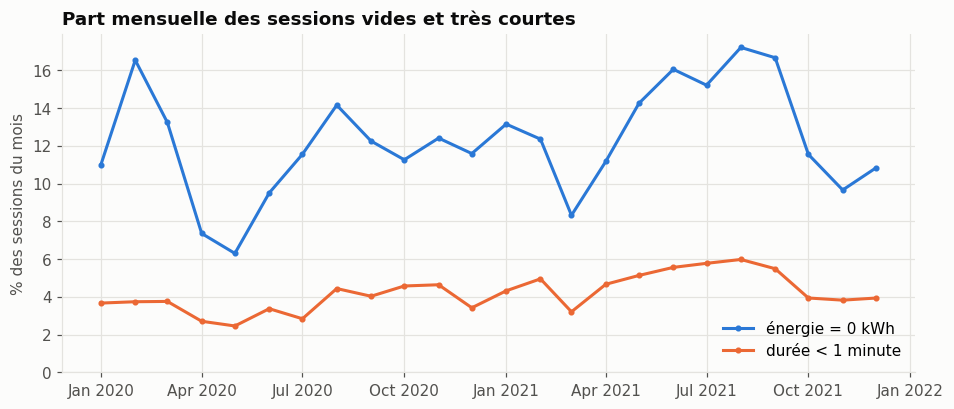

In [3]:
monthly = (raw.assign(month=raw["start_time"].dt.to_period("M").dt.to_timestamp(),
                      empty=raw["energy_kwh"].eq(0),
                      short=raw["duration_min"].lt(1))
           .query("start_time >= @start_date")
           .groupby("month")[["empty", "short"]].mean() * 100)

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["empty"], color=PALETTE[0], label="énergie = 0 kWh", marker="o", ms=3)
ax.plot(monthly.index, monthly["short"], color=PALETTE[1], label="durée < 1 minute", marker="o", ms=3)
ax.set_title("Part mensuelle des sessions vides et très courtes")
ax.set_ylabel("% des sessions du mois")
ax.set_ylim(bottom=0)
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

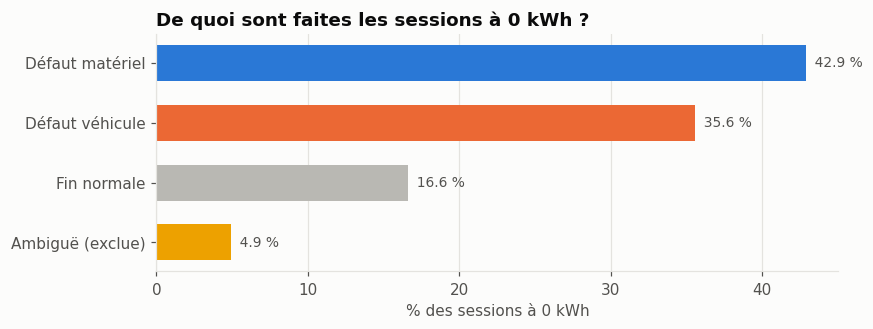

In [4]:
# Que contiennent les sessions vides ? Répartition par famille de cause.
empty_mix = (raw[raw["energy_kwh"].eq(0)]["family"].value_counts(normalize=True) * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(empty_mix.index[::-1], empty_mix.values[::-1],
        color=[FAMILY_COLORS[f] for f in empty_mix.index[::-1]], height=0.6)
for y, v in enumerate(empty_mix.values[::-1]):
    ax.text(v, y, f"  {v:.1f} %", va="center", fontsize=9, color=INK_2)
ax.set_title("De quoi sont faites les sessions à 0 kWh ?")
ax.set_xlabel("% des sessions à 0 kWh")
ax.grid(axis="y", visible=False)
plt.show()

**Constat** : la part mensuelle des sessions à 0 kWh varie entre environ 6 % (mai 2020) et 17 % (août 2021), celle des sessions de moins d'une minute entre 2,5 % et 6 %. Les variations sont progressives et suivent celles des défauts matériels (hausse à l'été 2021), sans rupture brutale et durable comme celle de « Faulty charging connection » en juin 2020 : c'est le comportement d'un phénomène réel, pas d'un changement d'enregistrement. Les sessions à 0 kWh se composent de 42,9 % de défauts matériels, 35,6 % de défauts véhicule, 16,6 % de fins normales et 4,9 % de causes ambiguës.


## Règle 3 · Durées extrêmes

In [5]:
extreme = raw[raw["duration_min"].eq(0) | raw["duration_min"].ge(23 * 60)]
extreme[["post_id", "site", "start_time", "duration_min", "energy_kwh", "end_cause"]].sort_values("duration_min")

,post_id,site,start_time,duration_min,energy_kwh,end_cause
225,1,Tourist Attraction,2020-12-23 13:33:29,0.000000,0.00,DC Output Fault
9042,7,Tourist Attraction,2021-12-28 15:12:23,0.000000,0.00,DC Output Fault
19539,1,Tourist Attraction,2021-08-06 12:50:16,0.000000,0.00,DC Output Fault
21323,3,Tourist Attraction,2021-05-21 14:53:21,0.000000,0.00,DC Output Fault
426735,92,Wholesale Market,2021-10-13 10:01:51,0.000000,0.00,DC Output Fault
254106,56,Bus Station,2020-01-18 12:41:21,1384.783333,46.24,Charging ends normally
296717,67,Government Agency,2020-10-06 14:14:14,1396.716667,42.31,Charging ends normally
19504,3,Tourist Attraction,2021-08-06 19:25:41,1402.850000,45.37,Charging ends normally
23904,11,Financial Industrial Park,2020-12-24 12:13:38,1425.033333,22.65,Charging ends normally
125268,21,Shopping Mall,2021-02-01 20:23:02,1430.716667,21.70,Charging ends normally


**Constat** : les 5 sessions de 0 minute délivrent toutes 0 kWh et se terminent toutes par « DC Output Fault » : ce sont des échecs immédiats, cohérents. Les 7 sessions de 23 heures ou plus se terminent toutes normalement avec 16 à 46 kWh délivrés : des véhicules restés branchés une journée, plausibles.


## Règle 4 · Familles de causes

In [6]:
compare = (pd.crosstab(raw["family"], raw["is_nonsystem_fault"].map({0: "non", 1: "oui"}))
           .rename_axis(index="notre famille", columns="is_nonsystem_fault des auteurs"))
compare

is_nonsystem_fault des auteurs,non,oui
notre famille,,
Ambiguë (exclue),15,8539
Défaut matériel,20276,24569
Défaut véhicule,20365,8170
Fin normale,359143,0


In [7]:
raw.groupby(["family", "end_cause"]).size().rename("sessions").to_frame()

sessions
family           end_cause                                                   
Ambiguë (exclue) Faulty charging connection                              8539
                 Vehicle Stake Interaction Failure                         15
Défaut matériel  AC Input Failure                                          99
                 AC switching device failure                                5
                 DC Output Fault                                        14813
                 DC switching device failure                             1058
                 Failure of non-system control loop components a...      6941
                 Other faults of the charging pile                      20114
                 Power conversion unit failure                           1653
                 System communications failure                            162
Défaut véhicule  BMS failure                                             8170
                 Vehicle charging faults                                 6429
                 Vehicle communications failure                         13936
Fin normale      Charging ends normally                                203201
                 User stops charging                                   155942

**Constat** : l'indicateur `is_nonsystem_fault` des auteurs (41 278 sessions) ne correspond pas à un défaut de borne. Il ne capte que 24 569 de nos 44 845 défauts matériels (54,8 %) : il ignore « Other faults of the charging pile » (20 114 sessions) et « System communications failure » (162). Et 40,5 % de ses sessions ne sont pas des défauts matériels : 8 539 « Faulty charging connection » et 8 170 défauts BMS, qui viennent de la batterie du véhicule.


## Règle 5 · Colonnes retirées

In [8]:
pd.DataFrame({
    "colonne": LEAKY_COLS + REDUNDANT_COLS,
    "raison": ["connue après la session (fuite)"] * len(LEAKY_COLS)
              + ["redondante (énergie × tarif) ou technique"] * len(REDUNDANT_COLS),
})

,colonne,raison
0,paid_at,connue après la session (fuite)
1,amount_paid,connue après la session (fuite)
2,amount,redondante (énergie × tarif) ou technique
3,electricity_cost,redondante (énergie × tarif) ou technique
4,service_charge,redondante (énergie × tarif) ou technique
5,order_created_at,redondante (énergie × tarif) ou technique


In [9]:
# Vérification de la redondance : le montant est-il expliqué par l'énergie ?
print(f"Corrélation énergie / montant : {raw['energy_kwh'].corr(raw['amount']):.3f}")

Corrélation énergie / montant : 0.964


## Règle 6 · Vie des bornes

Une borne n'existe qu'entre sa première et sa dernière session. Cette règle est appliquée lors de la construction de la table borne × jour (`daily_post_table` dans `target.py`) : les jours qui suivent la dernière session ne sont pas créés.

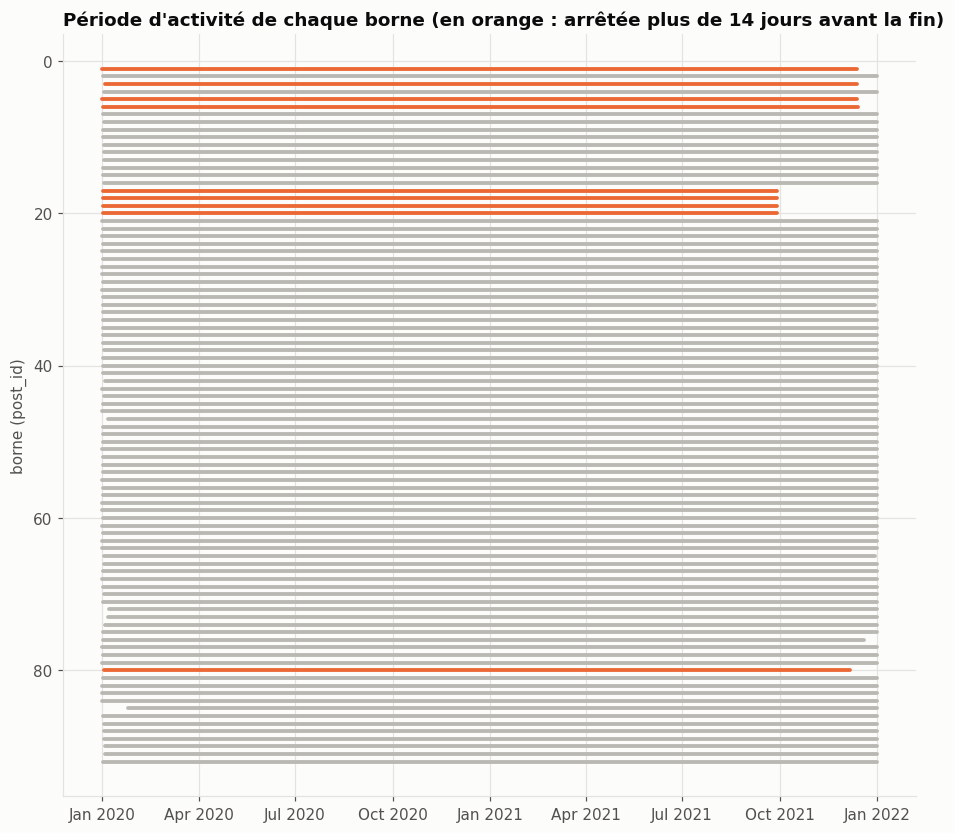

,post_id,site,first,last,arrêtée_tôt
0,1,Tourist Attraction,2020-01-01 01:42:01,2021-12-13 10:54:57,True
2,3,Tourist Attraction,2020-01-03 13:09:48,2021-12-13 10:59:45,True
4,5,Tourist Attraction,2020-01-01 01:45:07,2021-12-13 11:05:31,True
5,6,Tourist Attraction,2020-01-01 15:40:58,2021-12-13 12:23:47,True
16,17,Technology Park,2020-01-01 15:27:51,2021-09-28 20:08:03,True
17,18,Technology Park,2020-01-01 12:14:43,2021-09-28 20:30:53,True
18,19,Technology Park,2020-01-01 12:52:10,2021-09-28 19:16:27,True
19,20,Technology Park,2020-01-01 11:59:54,2021-09-28 20:51:02,True
79,80,Expressway Service District C,2020-01-02 15:40:37,2021-12-06 15:21:20,True
84,85,Wholesale Market,2020-01-25 16:32:30,2021-12-31 22:23:49,False


In [10]:
life = (raw[raw["start_time"] >= start_date]
        .groupby(["post_id", "site"])["start_time"].agg(first="min", last="max")
        .reset_index().sort_values("post_id"))
end_of_data = raw["start_time"].max()
life["arrêtée_tôt"] = life["last"] < end_of_data - pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(10, 9))
for _, r in life.iterrows():
    color = PALETTE[1] if r["arrêtée_tôt"] else NEUTRAL
    ax.plot([r["first"], r["last"]], [r["post_id"], r["post_id"]], color=color, lw=2.5, solid_capstyle="round")
ax.invert_yaxis()
ax.set_title("Période d'activité de chaque borne (en orange : arrêtée plus de 14 jours avant la fin)")
ax.set_ylabel("borne (post_id)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

life[life["arrêtée_tôt"] | (life["first"] > start_date + pd.Timedelta(days=14))]

**Constat** : 9 bornes s'arrêtent plus de 14 jours avant la fin des données : les 4 bornes du Technology Park (17 à 20) le 28 septembre 2021, la borne 80 le 6 décembre 2021, et 4 des 8 bornes du Tourist Attraction (1, 3, 5, 6) le 13 décembre 2021. Les 4 autres bornes de ce site restent actives : l'arrêt est partiel. La borne 85 démarre tardivement, le 25 janvier 2020.


## Application et sauvegarde

In [11]:
clean = clean_sessions(raw.drop(columns=["duration_min", "family"]))
path = save_interim(clean)

summary = pd.DataFrame({
    "étape": ["sessions brutes", "après règle 1 (période)", "sessions vides conservées",
              "sessions très courtes conservées", "colonnes avant", "colonnes après"],
    "valeur": [len(raw), len(clean), int(clean["is_empty"].sum()), int(clean["is_short"].sum()),
               raw.shape[1] - 2, clean.shape[1]],
})
print(f"Écrit : {path}  ({path.stat().st_size / 1e6:.1f} Mo)")
summary

Écrit : C:\dev\ev-reliability-data\interim\sessions.parquet  (11.1 Mo)


,étape,valeur
0,sessions brutes,441077
1,après règle 1 (période),441060
2,sessions vides conservées,54621
3,sessions très courtes conservées,19024
4,colonnes avant,24
5,colonnes après,15


In [12]:
# Relecture : le Parquet conserve-t-il les types ?
check = load_interim()
assert check.shape == clean.shape
check.dtypes.to_frame("type")

,type
user_id,int64
post_id,int64
site,object
district,object
energy_kwh,float64
start_time,datetime64[ns]
end_time,datetime64[ns]
temperature_c,float64
humidity_pct,int64
precipitation_mm,float64


Le CSV brut pèse environ 86 Mo et se lit en plusieurs secondes ; le Parquet est bien plus léger et conserve les types (dates, entiers sur 8 bits), sans rien à reconvertir.

## Ce qu'on retient

- **441 060 sessions propres**, 15 colonnes, écrites dans `interim/sessions.parquet` : 11,1 Mo contre 85,6 Mo pour le CSV, soit environ 8 fois moins, types conservés.
- **Nettoyage minimal, et c'est voulu** : seules 17 sessions sont retirées. Le travail a surtout consisté à décider ce qu'il ne fallait pas supprimer.
- **Sessions vides conservées** : 54 621 sessions, dont 42,9 % de défauts matériels. C'est le signal recherché.
- **Indicateurs des auteurs remplacés** : `is_nonsystem_fault` ne capte que 54,8 % des défauts matériels, et 40,5 % de son contenu n'en sont pas.
- **Arrêts de bornes documentés**, réutilisés plus tard pour le monitoring.
- Chaque règle est codée dans `clean.py` et protégée par un test dans `test_clean.py`.